# Airbnb prices: feature engineering and model evaluation

Estimate nightly listing prices using the supplied New York City Inside Airbnb snapshot. This notebook builds features, compares models on validation hosts, and evaluates the selected model on separate test hosts. All predictions and dollar errors refer to **USD per night**.

The original notebook plotted predictions for the full dataset, including training rows. Those plots could not measure generalisation. Here, no host appears in more than one partition. The final test set does not choose features, hyperparameters or the winning model.

In [1]:
from pathlib import Path
import sys

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits

# Open from the project directory or its parent.
ROOT = Path.cwd()
if not (ROOT / "features.py").exists() and (ROOT / "Airbnb/features.py").exists():
    ROOT = ROOT / "Airbnb"
if not (ROOT / "features.py").exists():
    raise FileNotFoundError("Open this notebook from the Airbnb project directory.")
sys.path.insert(0, str(ROOT))

from clean import clean_listings
from features import make_features, parse_amenities
from train import run_experiment, split_data, score_predictions
from predict import predict_prices

plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False,
                     "axes.spines.right": False})
pd.set_option("display.max_columns", 12)

## 1. Inspect the data

Keep every positive, finite observed price. Missing targets are removed; expensive listings are neither capped nor dropped. Missing feature values remain missing until model fitting. This avoids calculating imputation statistics from validation or test rows.

The model uses existing listing information available in this snapshot. Review history and availability would not be known for a completely new listing. Requested check-in/check-out dates are valid inputs, but quote totals, quoted nightly prices and estimated revenue are excluded because they reveal the target.

In [2]:
source = ROOT / "data/extracted/New_York_listings.csv"
if not source.exists():
    # Only the listings file is needed for the model, not calendar/reviews.
    source = ROOT / "data/raw/New_York_listings.csv.gz"
raw = pd.read_csv(source, low_memory=False)
data = clean_listings(raw)
output = ROOT / "data/processed/clean_New_York_listings.csv"
output.parent.mkdir(parents=True, exist_ok=True)
data.to_csv(output, index=False)

print(f"Source rows: {len(raw):,}; usable prices: {len(data):,}; removed: {len(raw)-len(data):,}")
print("Snapshot dates:", ", ".join(sorted(raw["last_scraped"].dropna().unique())))
print("Price range: ${:,.2f} to ${:,.2f}".format(data.price.min(), data.price.max()))
display(data.price.describe(percentiles=[.5, .9, .95, .99]).to_frame("Price (USD/night)"))
display((data.isna().mean().sort_values(ascending=False).head(12) * 100)
        .to_frame("Missing (%)").round(1))

Source rows: 30,259; usable prices: 21,515; removed: 8,744
Snapshot dates: 2026-06-14, 2026-06-15, 2026-06-22, 2026-06-23
Price range: $4.58 to $30,972.96


,Price (USD/night)
count,21515.000000
mean,278.229518
std,531.730477
min,4.580000
50%,174.690000
90%,528.900000
95%,759.000000
99%,1713.935000
max,30972.960000


,Missing (%)
host_since,100.0
instant_bookable,100.0
bedrooms,35.0
review_scores_location,28.3
reviews_per_month,28.2
review_scores_rating,28.2
review_scores_cleanliness,28.2
review_scores_checkin,28.2
review_scores_value,28.2
review_scores_communication,28.2


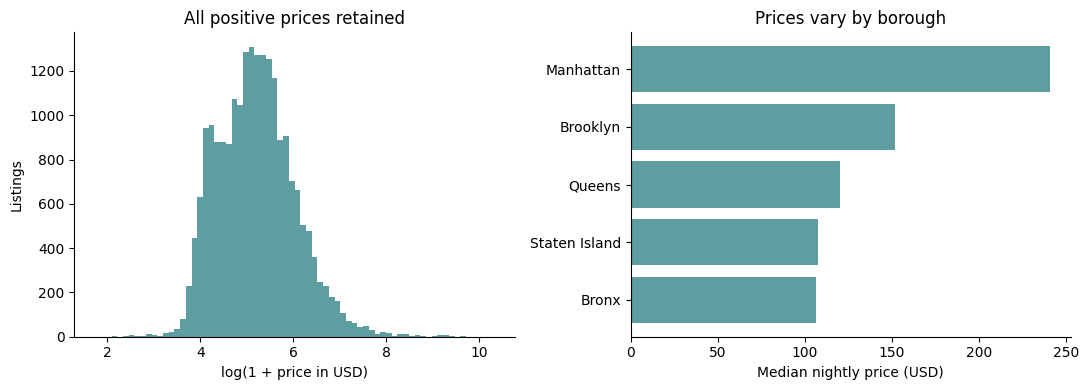

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(np.log1p(data.price), bins=70, color="cadetblue")
axes[0].set(xlabel="log(1 + price in USD)", ylabel="Listings", title="All positive prices retained")
boroughs = data.groupby("neighbourhood_group_cleansed").price.median().sort_values()
axes[1].barh(boroughs.index, boroughs.values, color="cadetblue")
axes[1].set(xlabel="Median nightly price (USD)", title="Prices vary by borough")
fig.tight_layout()
plt.show()

## 2. Engineer the features

The transformation lives in `features.py` and is included in each saved model, so training and prediction use the same functions.

| Feature group | Changes |
| --- | --- |
| Location | Latitude/longitude, property type, distances in km to Times Square, Central Park and the Financial District |
| Capacity | Recover bathroom counts from text, identify shared bathrooms, add guests per bedroom and beds/bathrooms per guest |
| Amenities | Parse JSON arrays correctly, recognise variants such as fast wifi and free street parking, count amenities, add workspace/outdoor/self-check-in flags |
| Reviews and host | Review subscores, recent review counts, review age/recency relative to the scrape date, host experience and listing count |
| Booking context | Minimum/maximum nights, availability, long-stay minimum, requested-stay length, lead time, seasonal check-in features |
| Missing information | Capacity missingness flags; remaining missing values are handled by the fitted model |

For example, `guests_per_bedroom = accommodates / bedrooms`, with zero denominators treated as missing. Geographic distances use the haversine formula and a 6,371 km Earth radius. Seasonal inputs use sine/cosine of the check-in month. No feature divides by price or otherwise uses it.

The benchmark preserves the original 22 features, amenity parser and random-forest settings. Its numeric imputation is now fitted on training rows only; this corrects the original full-dataset imputation.

In [4]:
inputs = data.drop(columns=["price", "id", "host_id"])
baseline_features = make_features(inputs, feature_set="baseline")
engineered_features = make_features(inputs)
print(f"Original features: {baseline_features.shape[1]}; engineered: {engineered_features.shape[1]}")

preview_columns = ["accommodates", "bedrooms", "bathrooms", "shared_bathroom",
                   "guests_per_bedroom", "amenity_count", "amenity_Wifi",
                   "distance_times_square_km", "quoted_stay_nights"]
display(engineered_features[preview_columns].head())

# Compare corrected amenity detection with the original parser.
flags = ["amenity_Wifi", "amenity_Kitchen", "amenity_Dryer", "amenity_Free_parking"]
display(pd.DataFrame({"Original count": baseline_features[flags].sum(),
                      "Corrected count": engineered_features[flags].sum()}))

Original features: 22; engineered: 81


,accommodates,bedrooms,bathrooms,shared_bathroom,guests_per_bedroom,amenity_count,amenity_Wifi,distance_times_square_km,quoted_stay_nights
0,2,1.0,1.0,1,2.0,49,1,12.511430,30
1,3,2.0,1.0,0,1.5,26,1,6.047341,30
2,1,NaN,1.0,1,NaN,18,1,6.001197,30
3,1,NaN,1.0,1,NaN,22,1,4.599598,30
4,2,NaN,1.0,0,NaN,50,1,7.410405,30


,Original count,Corrected count
amenity_Wifi,19884,21185
amenity_Kitchen,18038,18070
amenity_Dryer,3463,8054
amenity_Free_parking,0,10218


## 3. Reserve separate hosts for training, validation and testing

Two reproducible `GroupShuffleSplit` operations reserve approximately 60% of hosts for training, 20% for validation and 20% for testing. The fractions of listings differ because hosts have different numbers of properties. Neither listing IDs nor host IDs are predictors.

Model selection minimises **validation MAE in dollars**. We compare the original random forest, the same forest with the engineered features, two regularised histogram gradient-boosting models trained on log prices, and a boosting model trained on dollar prices with a Poisson loss (which keeps predictions positive). This also separates the feature improvements from changing the algorithm.

The winner and the original-feature baseline are then refitted on training + validation hosts. The same reserved test hosts evaluate both. The saved model uses those development hosts only; its test results apply to that exact fitted model. There is no test-based tuning or price-based trimming.

In [5]:
partitions = split_data(data)
host_sets = {name: set(data.iloc[index].host_id) for name, index in partitions.items()}
assert not host_sets["train"] & host_sets["validation"]
assert not host_sets["train"] & host_sets["test"]
assert not host_sets["validation"] & host_sets["test"]

partition_summary = pd.DataFrame([
    {"Partition": name, "Listings": len(index), "Hosts": len(host_sets[name])}
    for name, index in partitions.items()
]).set_index("Partition")
display(partition_summary)

,Listings,Hosts
Partition,,
train,12316,6353
validation,4558,2118
test,4641,2118


## 4. Train and select the model

Run this cell to reproduce the complete comparison. It can take several minutes, particularly for the random forests. The feature transformations and any learned encoders/imputers are fitted inside each pipeline. Native categorical encoding for histogram boosting treats categories as nominal, rather than assigning a numeric ordering.

Models fitted on log prices use `TransformedTargetRegressor` to invert the transform automatically. **Every `.predict()` below returns dollars. Do not apply `expm1` again.**

In [6]:
experiment = run_experiment(
    data,
    model_path=ROOT / "models/airbnb_price_model.pkl",
    report_dir=ROOT / "reports",
)
print("Selected using validation MAE:", experiment["selected"])
display(experiment["validation"].drop(columns="fit_seconds").round(4))

Original features + random forest: validation MAE $141.13; log RMSE 0.571
Engineered features + random forest: validation MAE $114.83; log RMSE 0.419
Engineered features + boosting (log, 350): validation MAE $109.63; log RMSE 0.398
Engineered features + boosting (log, 600): validation MAE $111.69; log RMSE 0.407
Engineered features + boosting (dollars, Poisson): validation MAE $118.20; log RMSE 0.431

Selected: Engineered features + boosting (log, 350)
          MAE_USD  RMSE_USD  R2_USD  MAE_log  RMSE_log  R2_log
Baseline  125.620   607.594   0.202    0.385     0.529   0.607
Selected   97.033   572.858   0.291    0.257     0.368   0.810
Saved model to /workspace/scratch/1f6233d2308f/work/Airbnb/models/airbnb_price_model.pkl
Selected using validation MAE: Engineered features + boosting (log, 350)


,MAE_USD,RMSE_USD,R2_USD,MAE_log,RMSE_log,R2_log
model,,,,,,
"Engineered features + boosting (log, 350)",109.6256,449.9900,0.2743,0.2768,0.3979,0.7885
"Engineered features + boosting (log, 600)",111.6892,453.6329,0.2625,0.2835,0.4067,0.7791
Engineered features + random forest,114.8340,459.6933,0.2426,0.2921,0.4194,0.7651
"Engineered features + boosting (dollars, Poisson)",118.1988,456.8139,0.2521,0.3037,0.4311,0.7518
Original features + random forest,141.1266,466.9401,0.2186,0.4203,0.5712,0.5643


## 5. Evaluate on the reserved test hosts

MAE is the mean absolute error in nightly dollars; RMSE gives large misses more weight. $R^2$ compares squared error with predicting the test mean. The log metrics show relative-price fit but do not measure dollar error. Dollar and log results can therefore tell different stories when there are very expensive listings.

In [7]:
test_scores = experiment["test"]
display(test_scores.round(4))
improvements = pd.Series({
    "MAE reduction (%)": 100 * (1 - test_scores.loc["Selected", "MAE_USD"]
                               / test_scores.loc["Baseline", "MAE_USD"]),
    "RMSE reduction (%)": 100 * (1 - test_scores.loc["Selected", "RMSE_USD"]
                                / test_scores.loc["Baseline", "RMSE_USD"]),
    "Log RMSE reduction (%)": 100 * (1 - test_scores.loc["Selected", "RMSE_log"]
                                    / test_scores.loc["Baseline", "RMSE_log"]),
})
display(improvements.round(2).to_frame("Change on the same test hosts"))

# Training errors are diagnostic only, never the model-selection criterion.
display(pd.DataFrame({
    "Development (fitted)": experiment["metadata"]["development_scores"],
    "Test (unseen hosts)": test_scores.loc["Selected"].to_dict(),
}).T.round(4))

,MAE_USD,RMSE_USD,R2_USD,MAE_log,RMSE_log,R2_log
Baseline,125.6202,607.5940,0.2022,0.3851,0.5292,0.6073
Selected,97.0330,572.8579,0.2908,0.2571,0.3681,0.8100


,Change on the same test hosts
MAE reduction (%),22.76
RMSE reduction (%),5.72
Log RMSE reduction (%),30.43


,MAE_USD,RMSE_USD,R2_USD,MAE_log,RMSE_log,R2_log
Development (fitted),59.8327,295.7370,0.6250,0.1644,0.2323,0.9226
Test (unseen hosts),97.0330,572.8579,0.2908,0.2571,0.3681,0.8100


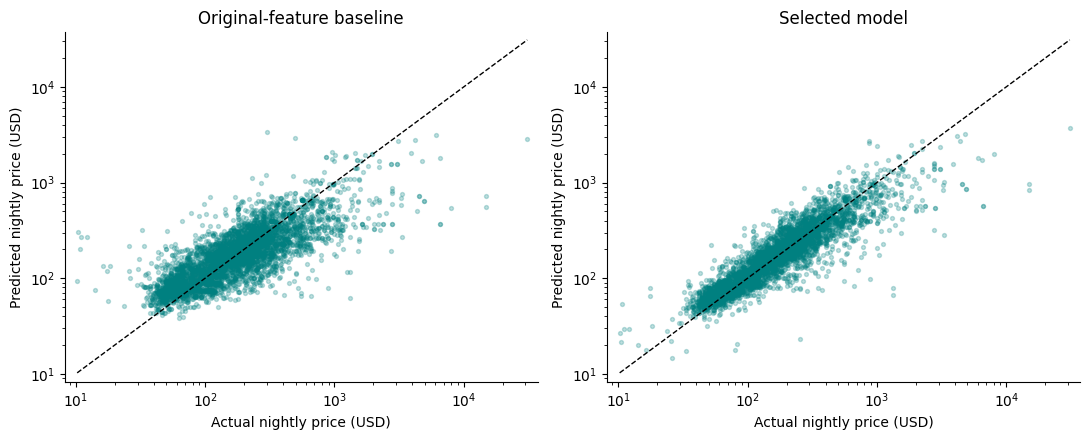

In [8]:
holdout = experiment["holdout"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
low = min(holdout.price.min(), holdout.prediction.min(), holdout.baseline_prediction.min())
high = max(holdout.price.max(), holdout.prediction.max(), holdout.baseline_prediction.max())
for ax, prediction, title in zip(axes, ["baseline_prediction", "prediction"],
                                 ["Original-feature baseline", "Selected model"]):
    ax.scatter(holdout.price, holdout[prediction], s=8, alpha=.25, color="teal")
    ax.plot([low, high], [low, high], color="black", linestyle="--", linewidth=1)
    ax.set(xscale="log", yscale="log", xlabel="Actual nightly price (USD)",
           ylabel="Predicted nightly price (USD)", title=title, xlim=(low*.8, high*1.2),
           ylim=(low*.8, high*1.2))
fig.tight_layout()
fig.savefig(ROOT / "reports/predicted_vs_actual.png", dpi=160, bbox_inches="tight")
plt.show()

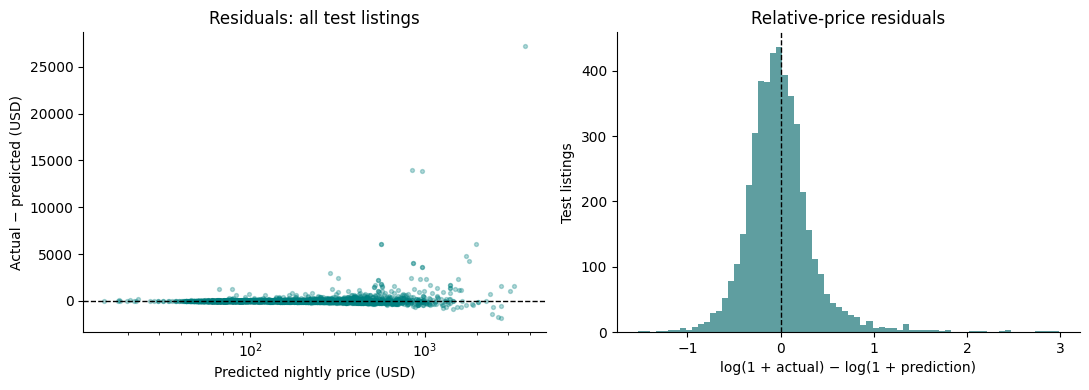

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(holdout.prediction, holdout.residual, s=8, alpha=.3, color="teal")
axes[0].axhline(0, color="black", linestyle="--", linewidth=1)
axes[0].set(xscale="log", xlabel="Predicted nightly price (USD)",
            ylabel="Actual − predicted (USD)", title="Residuals: all test listings")
log_residual = np.log1p(holdout.price) - np.log1p(holdout.prediction)
axes[1].hist(log_residual, bins=70, color="cadetblue")
axes[1].axvline(0, color="black", linestyle="--", linewidth=1)
axes[1].set(xlabel="log(1 + actual) − log(1 + prediction)",
            ylabel="Test listings", title="Relative-price residuals")
fig.tight_layout()
fig.savefig(ROOT / "reports/residuals.png", dpi=160, bbox_inches="tight")
plt.show()

In [10]:
diagnostics = holdout.assign(
    absolute_error=(holdout.price - holdout.prediction).abs(),
    baseline_absolute_error=(holdout.price - holdout.baseline_prediction).abs(),
)
by_room = diagnostics.groupby("room_type").agg(
    listings=("price", "size"), median_price=("price", "median"),
    baseline_MAE_USD=("baseline_absolute_error", "mean"),
    selected_MAE_USD=("absolute_error", "mean"),
)
display(by_room.round(2))

# This price breakdown describes errors after evaluation; it does not filter data.
price_bins = pd.cut(diagnostics.price, [0, 100, 250, 500, 1000, np.inf],
                    labels=["up to $100", "$100–250", "$250–500", "$500–1,000", "over $1,000"])
by_price = diagnostics.groupby(price_bins, observed=True).agg(
    listings=("price", "size"), baseline_MAE_USD=("baseline_absolute_error", "mean"),
    selected_MAE_USD=("absolute_error", "mean"),
)
display(by_price.round(2))

,listings,median_price,baseline_MAE_USD,selected_MAE_USD
room_type,,,,
Entire home/apt,2298,217.78,125.71,95.24
Hotel room,184,619.50,739.48,671.26
Private room,2122,94.29,73.03,49.57
Shared room,37,52.21,83.47,74.59


,listings,baseline_MAE_USD,selected_MAE_USD
price,,,
up to $100,1273,33.94,16.34
$100–250,1987,53.99,40.40
$250–500,926,115.81,85.69
"$500–1,000",319,301.67,220.91
"over $1,000",136,1684.10,1466.43


## 6. Load the saved model and predict

These are real, held-out listings with their original input features. For your own CSV, provide raw listing columns such as `room_type`, `accommodates`, location and a JSON `amenities` array. Supply requested-stay dates if available. Missing optional information is handled by the fitted pipeline, but sparse inputs may give less reliable estimates.

In [11]:
sample_indices = experiment["splits"]["test"][:5]
sample = inputs.iloc[sample_indices].copy()
with threadpool_limits(limits=4):
    results = predict_prices(sample, ROOT / "models/airbnb_price_model.pkl")
results["actual_price_USD"] = data.price.iloc[sample_indices].to_numpy()
display(results[["neighbourhood_group_cleansed", "neighbourhood_cleansed", "room_type",
                 "accommodates", "actual_price_USD", "predicted_price_USD"]])

# Confirm that the saved pipeline reproduces the evaluated predictions.
np.testing.assert_allclose(results.predicted_price_USD,
                           experiment["holdout"].prediction.head(5).round(2))

,neighbourhood_group_cleansed,neighbourhood_cleansed,room_type,accommodates,actual_price_USD,predicted_price_USD
6,Brooklyn,Fort Greene,Entire home/apt,4,154.87,338.45
12,Manhattan,Hell's Kitchen,Entire home/apt,2,148.04,173.82
23,Queens,Astoria,Private room,2,101.33,117.66
25,Manhattan,East Village,Entire home/apt,4,238.20,257.99
48,Manhattan,Little Italy,Private room,1,111.58,94.87


## What the comparison establishes

The scores above measure performance on different hosts from the same supplied snapshot. The validation table shows whether the engineered features help the original forest and which candidate earns the lowest validation dollar MAE. The test table reports the reserved evaluation without changing the selection afterwards.

Large residuals, especially for expensive properties, remain part of the result. A log-price objective can underestimate the high-price tail; it is not an unbiased estimate of the arithmetic mean price. This is an estimate of observed listing prices, not realised booking prices or future demand. A separate later snapshot would be needed to test performance over time. Missing-price listings are outside this evaluation, and the missingness may be systematic.

`models/airbnb_price_model.pkl` contains the selected feature/encoding/model pipeline. `reports/` contains the exact metrics, validation comparison, test predictions, split assignments and diagnostic figures. The supplied README describes the command-line workflow.